# Exploration vs. exploitation: ε-greedy, UCB1 and Thompson sampling

This notebook is the analysis behind **Restaurant Week**. A *multi-armed bandit* is the simplest reinforcement-learning problem: there is no state, only a set of actions ("arms") with unknown average rewards. Each step you pick one arm and observe a noisy reward. The goal is to collect as much reward as possible, which means balancing:

- **exploitation**: pulling the arm that looks best so far, and
- **exploration**: pulling other arms to learn whether they are actually better.

We measure performance with **regret**: the reward lost compared to always pulling the best arm,

$$R(T) = \sum_{t=1}^{T} \left(\mu^* - \mu_{a_t}\right) = \sum_a \Delta_a \, \mathbb{E}[n_a(T)],$$

where $\Delta_a = \mu^* - \mu_a$ is the gap of arm $a$ and $n_a(T)$ how often it was pulled. Good algorithms keep $R(T)$ growing like $\log T$; naive ones grow linearly.

In [1]:
import sys, pathlib

# True when this notebook runs in the browser (JupyterLite / Pyodide) instead of a local Jupyter.
IN_BROWSER = sys.platform == "emscripten"
if IN_BROWSER:
    import piplite
    await piplite.install(["numpy", "matplotlib"])

# Make the local `bandits` package importable without installing it
# (it sits next to this notebook in the browser, one folder up when run from bandits/notebooks).
for folder in (pathlib.Path.cwd(), pathlib.Path.cwd().parent):
    if (folder / "bandits" / "__init__.py").exists():
        sys.path.insert(0, str(folder))
        break

# The browser is a few times slower than native Python, so it averages fewer runs.
SCALE = 0.3 if IN_BROWSER else 1.0
def runs(n):
    return max(10, int(n * SCALE))

import numpy as np
import matplotlib.pyplot as plt
from bandits import (EpsilonGreedy, UCB1, GaussianThompson, BernoulliThompson,
                     StarRatingBandit, BernoulliBandit, random_neighbourhood,
                     run_episode, run_experiment, lai_robbins_bound)

plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"ε-greedy": "#D1492E", "UCB1": "#2B66C7", "Thompson sampling": "#8A45C2"}

## 1. The setting

Each "neighbourhood" has 8 restaurants. One kitchen is clearly the best, one is a close runner-up and the rest are middling. A meal is rated 1–5 stars (half-star steps) around the kitchen's true quality with noise σ = 0.8 stars. Agents learn on the unit scale $(\text{stars}-1)/4$.

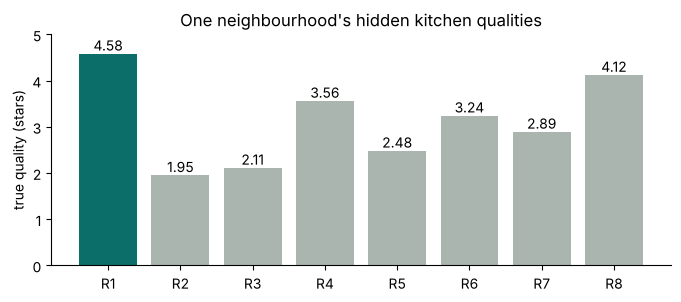

In [2]:
means = random_neighbourhood(8, seed=4)
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.bar([f"R{i+1}" for i in range(8)], means, color=["#0B6E68" if m == means.max() else "#A9B5AE" for m in means])
ax.bar_label(bars, fmt="%.2f"); ax.set_ylim(0, 5); ax.set_ylabel("true quality (stars)")
ax.set_title("One neighbourhood's hidden kitchen qualities");

## 2. One week, three strategies

A single run of 20 dinners. Thanks to *common random numbers* (each restaurant has its own reward stream) all three agents would receive the same rating on, say, their third visit to restaurant 5. Differences come from decisions.

In [3]:
def agents(eps=0.1, c=0.3):
    return {
        "ε-greedy": lambda k, s: EpsilonGreedy(k, epsilon=eps, seed=s),
        "UCB1": lambda k, s: UCB1(k, c=c, seed=s),
        "Thompson sampling": lambda k, s: GaussianThompson(k, seed=s),
    }

for name, make in agents().items():
    env = StarRatingBandit(means, seed=4)
    ep = run_episode(make(8, 1), env, horizon=20)
    print(f"{name:<18} choices: {' '.join(str(a + 1) for a in ep.actions)}   stars missed: {ep.cumulative_regret[-1]:.2f}")
print("best restaurant:", int(np.argmax(means)) + 1)

ε-greedy           choices: 7 7 7 7 7 7 7 7 8 8 8 8 8 8 8 8 8 8 8 8   stars missed: 19.04
UCB1               choices: 4 5 7 8 1 2 6 3 8 1 1 1 8 1 1 1 8 1 1 8   stars missed: 13.55
Thompson sampling  choices: 5 8 8 7 2 8 8 1 1 1 1 1 1 1 1 1 1 6 1 4   stars missed: 10.62
best restaurant: 1


## 3. Averaged over many neighbourhoods

One week is noise. Here every agent plays 150 fresh neighbourhoods for 1,000 dinners each (45 when the notebook runs in your browser, so it finishes quickly); we plot mean cumulative regret with a ±1 standard deviation band.

ε-greedy           R(T) =  233.3 ± 117.9   best place in last 10%: 86.5%
UCB1               R(T) =   66.0 ±  13.7   best place in last 10%: 97.0%
Thompson sampling  R(T) =   45.1 ±  15.2   best place in last 10%: 98.8%


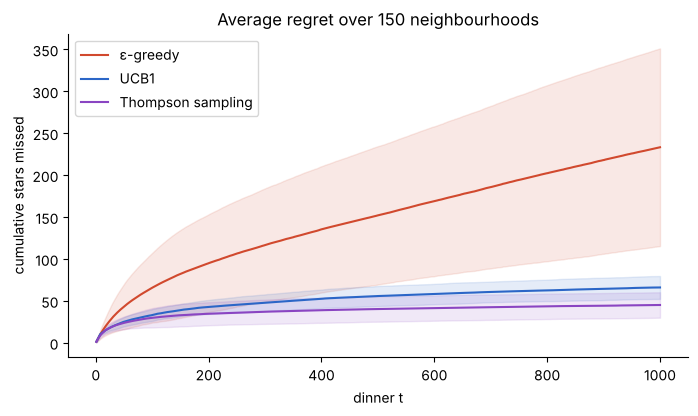

In [4]:
def neighbourhood_env(seed):
    return StarRatingBandit(random_neighbourhood(8, seed), sigma=0.8, seed=seed)

T, RUNS = 1000, runs(150)
results = run_experiment(agents(), neighbourhood_env, horizon=T, runs=RUNS, seed=0)

fig, ax = plt.subplots()
x = np.arange(1, T + 1)
for name, r in results.items():
    ax.plot(x, r.mean, label=name, color=COLORS[name])
    ax.fill_between(x, np.maximum(0, r.mean - r.std), r.mean + r.std, color=COLORS[name], alpha=0.12)
ax.set(xlabel="dinner t", ylabel="cumulative stars missed", title=f"Average regret over {RUNS} neighbourhoods")
ax.legend();

for name, r in results.items():
    print(f"{name:<18} R(T) = {r.final_regret:6.1f} ± {r.std[-1]:5.1f}   best place in last 10%: {r.optimal_rate[-T//10:].mean():.1%}")

**Reading the curves.** Constant-ε greedy keeps spending about ε of its pulls on random arms forever, so its regret ends up a straight line with slope ≈ ε × (average gap). UCB1 and Thompson sampling explore less as their uncertainty shrinks, so their curves bend flat. On a log time axis, logarithmic regret becomes a straight line:

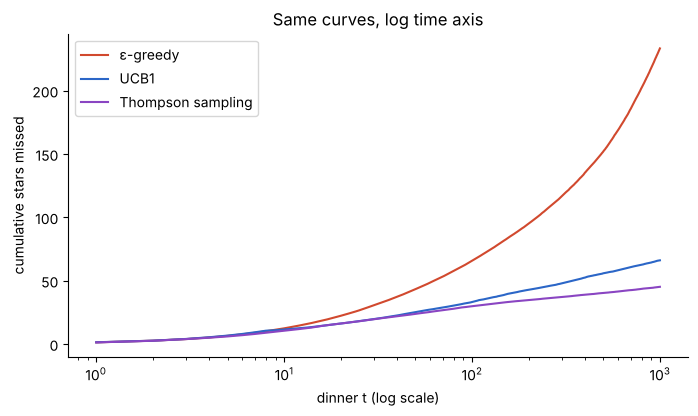

In [5]:
fig, ax = plt.subplots()
for name, r in results.items():
    ax.plot(x, r.mean, label=name, color=COLORS[name])
ax.set_xscale("log"); ax.set(xlabel="dinner t (log scale)", ylabel="cumulative stars missed", title="Same curves, log time axis")
ax.legend();

## 4. The Lai–Robbins lower bound

For a fixed bandit, no *consistent* policy can beat

$$\liminf_{T\to\infty} \frac{R(T)}{\ln T} \ge \sum_{a:\,\Delta_a>0} \frac{\Delta_a}{\mathrm{KL}(\mu_a, \mu^*)}.$$

We check it on a fixed Bernoulli bandit, where Thompson sampling with a Beta(1, 1) prior is known to be asymptotically optimal.

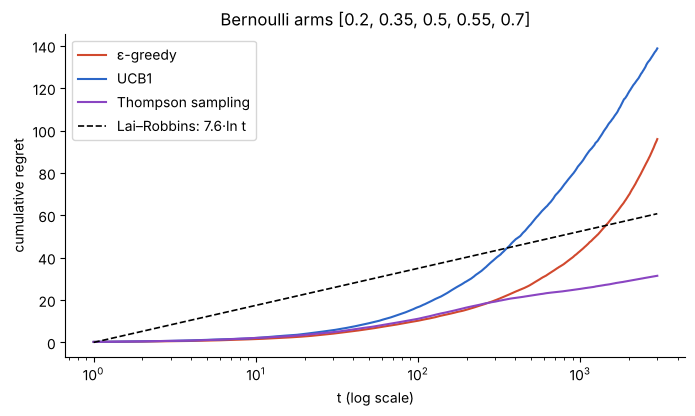

In [6]:
B_MEANS = [0.20, 0.35, 0.50, 0.55, 0.70]
C = lai_robbins_bound(B_MEANS)
bern = {
    "ε-greedy": lambda k, s: EpsilonGreedy(k, epsilon=0.1, seed=s),
    "UCB1": lambda k, s: UCB1(k, seed=s),            # textbook c = √2 for rewards in [0, 1]
    "Thompson sampling": lambda k, s: BernoulliThompson(k, seed=s),
}
TB = 3000
bres = run_experiment(bern, lambda s: BernoulliBandit(B_MEANS, seed=s), horizon=TB, runs=runs(60), seed=1)

fig, ax = plt.subplots()
xb = np.arange(1, TB + 1)
for name, r in bres.items():
    ax.plot(xb, r.mean, label=name, color=COLORS[name])
ax.plot(xb, C * np.log(xb), "k--", lw=1.2, label=f"Lai–Robbins: {C:.1f}·ln t")
ax.set_xscale("log"); ax.set(xlabel="t (log scale)", ylabel="cumulative regret", title="Bernoulli arms " + str(B_MEANS))
ax.legend();

Thompson sampling stays below the dashed line. That is not a contradiction: the bound only constrains the growth rate as $T \to \infty$, and good algorithms often sit under $C \ln t$ at finite horizons. UCB1 with the textbook $c=\sqrt{2}$ explores far more cautiously: at $t = 3{,}000$ it is still in its steep phase and only later bends into a logarithmic curve, with a much larger constant. Constant-ε greedy eventually turns into a straight line on a linear axis (exponential-looking here on the log axis).

## 5. How much exploration is right?

Sweep ε for ε-greedy and c for UCB1 at T = 1,000. Too little exploration risks locking onto a bad arm; too much wastes pulls forever.

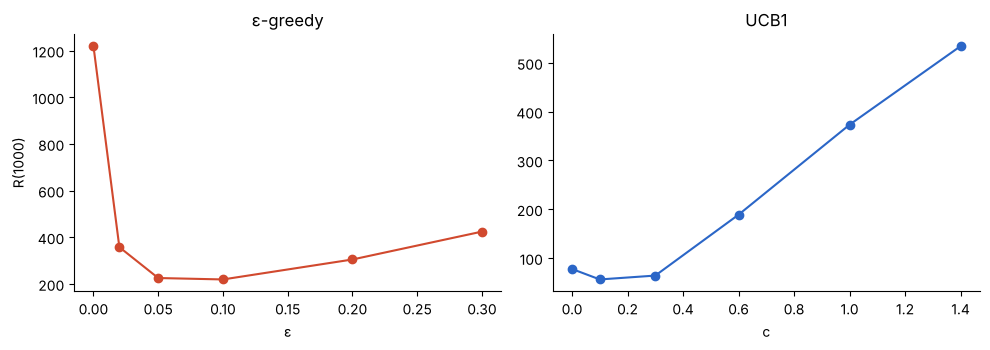

In [7]:
eps_grid = [0.0, 0.02, 0.05, 0.1, 0.2, 0.3]
c_grid = [0.0, 0.1, 0.3, 0.6, 1.0, 1.4]
eps_reg = [run_experiment({"e": lambda k, s, e=e: EpsilonGreedy(k, epsilon=e, seed=s)}, neighbourhood_env, 1000, runs(60), seed=2)["e"].final_regret for e in eps_grid]
c_reg = [run_experiment({"u": lambda k, s, c=c: UCB1(k, c=c, seed=s)}, neighbourhood_env, 1000, runs(60), seed=2)["u"].final_regret for c in c_grid]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.plot(eps_grid, eps_reg, "o-", color=COLORS["ε-greedy"]); a1.set(xlabel="ε", ylabel="R(1000)", title="ε-greedy")
a2.plot(c_grid, c_reg, "o-", color=COLORS["UCB1"]); a2.set(xlabel="c", title="UCB1")
fig.tight_layout();

## 6. Short horizons shrink the differences

The game is only 20 dinners long. With 8 arms, UCB1 spends its first 8 pulls trying every arm once, and nobody has time to learn much. The averages end up close and the spread is wide, which is why a human can easily beat the algorithms in a single week. The long-run picture above is where the strategies really separate.

ε-greedy           mean 21.28   median 20.23
UCB1               mean 16.08   median 15.74
Thompson sampling  mean 15.57   median 15.37


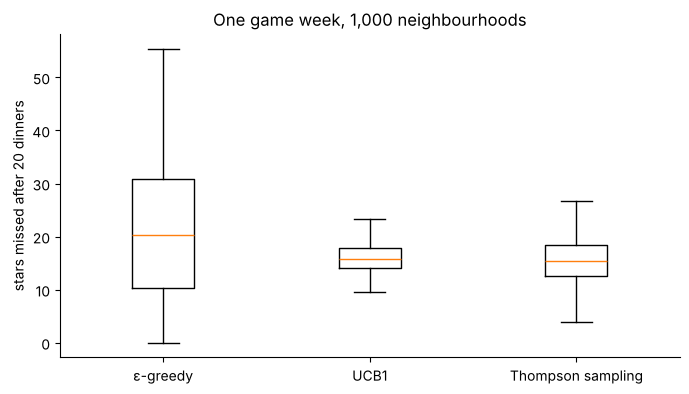

In [8]:
short = run_experiment(agents(), neighbourhood_env, horizon=20, runs=runs(1000), seed=3)
fig, ax = plt.subplots()
ax.boxplot([r.cumulative_regret[:, -1] for r in short.values()], tick_labels=list(short), showfliers=False)
ax.set(ylabel="stars missed after 20 dinners", title=f"One game week, {runs(1000):,} neighbourhoods");
for name, r in short.items():
    print(f"{name:<18} mean {r.final_regret:5.2f}   median {np.median(r.cumulative_regret[:, -1]):5.2f}")

## Takeaways

1. **Regret is the right yardstick.** It judges choices, not luck, and its growth rate separates naive from principled exploration.
2. **Constant ε ⇒ linear regret.** ε-greedy is simple and often fine, but needs a decaying ε to be competitive in the long run.
3. **Optimism (UCB1) and posterior sampling (Thompson) ⇒ logarithmic regret.** They explore in proportion to uncertainty.
4. **Thompson sampling is usually the strongest in practice**, and matches the Lai–Robbins lower bound on Bernoulli bandits.
5. **The horizon matters.** With very few steps, committing early can beat careful exploration.

These ideas carry over to full reinforcement learning: ε-greedy action selection in Q-learning/DQN, UCB in Monte Carlo Tree Search (UCT, AlphaGo), and posterior sampling in Bayesian RL.